### 검색 Tool이 필요한 이유
- LLM의 파라미터에 담긴 지식은 최신 사실을 보장하지 않음
- 웹 검색 도구는 외부 자료를 가져오는 역할
- 검색 결과 자체가 틀리거나 악성 지시를 포함할 수 있으므로 신뢰할 수 있는 출처와 날짜를 확인

```
사용자 -> LLM -> 검색 필요? -> 아니요 -> 답변
                                네  -> 검색  Tool -> 결과 확인 -> LLM -> 답변
```

# **1. Tavily**

AI 애플리케이션과 Agent가 웹에서 정보를 검색하고, 검색 결과의 제목/주소/본문 일부를 구조화된 데이터로 받도록 지원하는 검색 API 서비스

In [2]:
import os
from dotenv import load_dotenv

In [4]:
load_dotenv()
OPENAI_API_KEY=bool(os.getenv("OPENAI_API_KEY"))
TAVILY_API_KEY=bool(os.getenv("TAVILY_API_KEY"))
OPENAI_MODEL=bool(os.getenv("OPENAI_MODEL"))

print("OPENAI_API_KEY: ", OPENAI_API_KEY, " | TAVILY_API_KEY: ", TAVILY_API_KEY, " | OPENAI_MODEL", OPENAI_MODEL)

OPENAI_API_KEY:  True  | TAVILY_API_KEY:  True  | OPENAI_MODEL True


In [15]:
MODEL_NAME = os.getenv("OPENAI_MODEL", "gpt-6-luna")

In [16]:
from langchain_openai import ChatOpenAI

In [17]:
def make_llm():
    # API 키가 없으면 오류 메시지를 출력하고 None 반환
    if not OPENAI_API_KEY:
        print("KEY ERROR!")
        return None

    # OpenAI LLM 객체 생성 및 반환
    return ChatOpenAI(
        model=MODEL_NAME,        # 사용할 모델 이름
        reasoning_effort="none", # 추론 노력 수준 설정 (추론 최소화)
        timeout=30,              # API 응답 대기 시간 (최대 30초)
        max_retries=2,           # API 요청 실패 시 최대 재시도 횟수
        temperature=0            # 응답의 무작위성 설정 (0: 일관성 높은 응답)
    )

In [18]:
llm = make_llm()

In [19]:
from tavily import TavilyClient  # pip install tavily

In [21]:
# Tavily API 키가 존재하는 경우
if TAVILY_API_KEY:
    # Tavily 검색 클라이언트 생성
    tavily_client = TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))

    # 웹 검색 실행 (최대 3개 결과 반환)
    raw_search = tavily_client.search(query="랭그래프는 뭐야?", max_results=3)

    # 검색 결과의 최상위 키 출력
    print("최상위 키: ", list(raw_search.keys()))

    # 검색 결과를 하나씩 순회 (인덱스는 1부터 시작)
    for idx, item in enumerate(raw_search.get("results", []), start=1):
        print(f"\n[{idx}]제목: ", item.get("title", ""))               # 검색 결과 제목
        print("주소: ", item.get("url", ""))                 # 검색 결과 URL
        print("요약: ", str(item.get("content", ""))[:200])  # 검색 내용의 앞 200자 출력
else:
    # API 키가 없는 경우
    print("KEY ERROR!!")

최상위 키:  ['query', 'follow_up_questions', 'answer', 'images', 'results', 'response_time', 'request_id']

[1]제목:  LangGraph란 무엇이고 언제 쓰면 좋을까?
주소:  https://velog.io/@ohback/LangGraph
요약:  여기서 등장하는 게 LangGraph다. 이름 그대로 그래프(노드/엣지)로 LLM 애플리케이션의 흐름을 설계한다.  
 LangChain이 블록(모델·프롬프트·툴)을 잘 조립하게 해주는 공구상자라면, LangGraph는 그 블록들이 언제, 어떤 조건으로, 어떤 상태를 들고 움직일지를 정밀하게 오케스트레이션하는 조감도 + 신호등에 가깝다.

  

## 그래

[2]제목:  LangGraph란 무엇인가요? | IBM
주소:  https://www.ibm.com/kr-ko/think/topics/langgraph
요약:  # LangGraph란 무엇인가요?

Bryan Clark 

Senior AI Advocate

## LangGraph란 무엇인가요?

LangChain에서 만든 LangGraph는 복잡한 생성형 AI 에이전트 워크플로를 구축, 배포, 관리하도록 설계된 오픈 소스 AI 에이전트 프레임워크입니다. 이는 사용자가 확장가능한 방식으로 대규모 언어 모델(LLM)

[3]제목:  꿈 많은 사람의 이야기
주소:  https://lsjsj92.tistory.com/696
요약:  ## LangGraph란?

LangGraph는 LLM을 기반으로 상태를 유지하고(Stateful), 여러 단계에 걸쳐 작동하는(multi-step) 에이전트를 구축하기 위한 라이브러리입니다. 기존의 LangChain이 LLM과 외부 도구를 '연쇄적으로(chaining)' 연결하는 데 중점을 두었다면, LangGraph는 이러한 연결 구조를 순환(cycle


In [38]:
from langgraph.graph import StateGraph, START, END
from langgraph.graph import MessagesState
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_tavily import TavilySearch # pip install langchain_tavily

In [ ]:
# LLM과 Tavily API 키가 모두 존재하는 경우
if llm is not None and TAVILY_API_KEY:
    # Tavily 검색 도구 생성 (최대 3개 결과 반환)
    search_tool = TavilySearch(max_results=3)

    # LLM에 검색 도구 연결
    search_llm = llm.bind_tools([search_tool])

    # LLM이 메시지를 받아 응답하는 노드
    def search_agent_node(state: MessagesState):
        response = search_llm.invoke(state["messages"])  # 현재 메시지를 LLM에 전달
        return {"messages": [response]}                  # LLM 응답 반환

    # LangGraph 상태 그래프 생성
    search_builder = StateGraph(MessagesState)

    # 노드 추가
    search_builder.add_node("agent", search_agent_node)  # LLM 응답 생성 노드
    search_builder.add_node("tools", ToolNode([search_tool]))  # 검색 도구 실행 노드

    # 그래프 연결
    search_builder.add_edge(START, "agent")  # 시작 → LLM
    search_builder.add_conditional_edges("agent", tools_condition)  # 도구 호출 여부 판단
    search_builder.add_edge("tools", "agent")  # 검색 결과를 다시 LLM에 전달

    # 그래프 컴파일 (실행 가능한 그래프로 변환)
    search_graph = search_builder.compile()

    # 사용자 질문을 입력하여 그래프 실행
    result = search_graph.invoke(
        {"messages": [{"role": "user", "content": "LangGraph 최신 공식 문서를 찾아줘"}]},
        config={"recursion_limit": 10}  # 그래프 실행 단계 최대 10회 제한
    )

    # 전체 메시지를 순회하며 각 메시지의 앞 500자 출력
    for message in result["messages"]:
        print(type(message).__name__, str(message.content)[:500])

else:
    # LLM 또는 Tavily API 키가 없는 경우
    print("KEY ERROR!")


# bind_tools(): LLM에 사용할 도구 연결
# MessagesState: 대화 메시지를 관리하는 상태 구조
# StateGraph(): 상태 기반 그래프 생성
# add_node(): 그래프에 노드 추가
# add_edge(): 노드 간 실행 경로 연결
# add_conditional_edges(): 조건에 따라 다음 실행 경로 결정
# tools_condition: LLM이 도구를 호출하면 도구 노드로, 아니면 종료로 이동
# ToolNode(): LLM이 요청한 도구 실행
# compile(): 그래프를 실행 가능한 형태로 변환
# invoke(): 그래프 실행 및 최종 상태 반환

HumanMessage LangGraph 최신 공식 문서를 찾아줘
AIMessage 
ToolMessage {"query": "LangGraph official documentation latest LangChain docs", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://docs.langchain.com/oss/python/langgraph/overview", "title": "LangGraph overview - Docs by LangChain", "content": "Trusted by companies shaping the future of agents—including Klarna, Uber, J.P. Morgan, and more—LangGraph is a low-level orchestration framework and runtime for building, managing, and deploying long-running, stateful agents. Lang
AIMessage LangGraph **최신 공식 문서**는 LangChain 공식 문서 사이트에서 확인할 수 있습니다.

- **LangGraph 개요**: https://docs.langchain.com/oss/python/langgraph/overview
- **LangGraph 공식 문서 홈**: https://docs.langchain.com/
- **LangGraph GitHub 저장소**: https://github.com/langchain-ai/langgraph

문서에서 다루는 주요 내용은 다음과 같습니다.

- 그래프 기반 워크플로 구축
- 상태(State) 관리
- 노드와 엣지 구성
- 조건부 라우팅
- 체크포인트와 영속성(Persistence)
- 스트리밍
- Human-in-the-loop
- 장시간 실행되는 Stateful Agent
- LangSmi

### Reflection vs Reflexion
- Reflection(반성)은 작성한 초안을 스스로 검토하고 고치는 작업
- Reflexion(확장형 반성)은 여러 번의 시도에서 실패 원인과 피드백을 기억해 다음 시도 전략까지 바꾸는 접근
> 공통점은 둘 다 "자기 평가"가 항상 맞다는 뜻은 아님

- 구성 요소: 초안 생성 -> 평가 -> 피드백 -> 수정 -> 재평가
- 평가 기준: 사실 정확성, 근거, 형식, 독자 수준, 빠진 항목
- 종료 조건: 통과 기준 만족, 최대 시도 횟수, 비용 상한
- 흔한 오류: LLM이 점수만 매기고 수정 지시를 전달하지 않은 것

In [32]:
from typing import TypedDict, Literal

In [ ]:
# TypedDict: 딕셔너리의 키와 값의 자료형 정의
# ReviewState: 그래프에서 관리할 상태 데이터 구조
class ReviewState(TypedDict):
    topic: str      # 작성할 주제
    draft: str      # 작성된 초안
    feedback: str   # 검토 결과 및 수정 요청
    approved: bool  # 초안 승인 여부
    attempts: int   # 초안 작성 횟수

# write_draft(): 초안 작성 및 작성 횟수 증가
# state: 그래프에서 관리하는 현재 상태 데이터
# 초안 작성 또는 수정
def write_draft(state: ReviewState):
    text = f"{state['topic']}은 중요한 개념입니다."  # 주제를 이용해 초안 작성

    # 재작성 시 구체적인 예시 추가
    if state["attempts"] > 0:
        text += " 예시: 사용자의 질문을 검색하고 근거를 붙여 답합니다."

    return {"draft": text, "attempts": state["attempts"] + 1}  # 초안과 작성 횟수 반환

# review_draft(): 초안에 예시가 있는지 확인하여 승인 여부 결정
# 초안의 통과 여부 판단
def review_draft(state: ReviewState):
    good = "예시:" in state["draft"]  # 초안에 '예시:'가 포함되어 있는지 확인

    return {
        "approved": good,  # 예시가 있으면 True, 없으면 False
        "feedback": "통과" if good else "구체적인 예시를 추가하세요"  # 검토 결과 반환
    }

# review_route(): 승인 여부와 작성 횟수에 따라 실행 경로 결정
# Literal["write", "finish"]: 반환 가능한 값을 "write"와 "finish"로 제한하는 타입 힌트
# 조건 함수: 다시 작성할지 종료할지 결정
def review_route(state: ReviewState) -> Literal["write", "finish"]:
    # 승인되었거나 작성 횟수가 3회 이상이면 종료, 아니면 재작성
    return "finish" if state["approved"] or state["attempts"] >= 3 else "write"

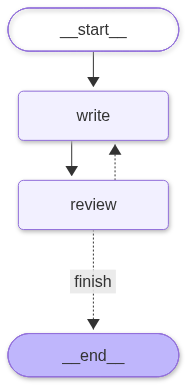

In [39]:
review_builder = StateGraph(ReviewState)
review_builder.add_node("write", write_draft)
review_builder.add_node("review", review_draft)
review_builder.add_edge(START, "write")
review_builder.add_edge("write", "review")
review_builder.add_conditional_edges("review", review_route, {"write": "write", "finish": END})
review_graph = review_builder.compile()
review_graph

In [41]:
review_result = review_graph.invoke({"topic": "RAG", "draft": "", "feedback": "", "approved": False, "attempts": 0})
print(review_result)

{'topic': 'RAG', 'draft': 'RAG은 중요한 개념입니다. 예시: 사용자의 질문을 검색하고 근거를 붙여 답합니다.', 'feedback': '통과', 'approved': True, 'attempts': 2}


In [42]:
from pydantic import BaseModel, Field

In [ ]:
class DraftGrade(BaseModel):
    score: int = Field(ge=0, le=5, description="정확성/구체성 기준 0~5점")
    strengths: str = Field(description="잘된 점")
    weaknesses: str = Field(description="부족한 점")
    revision_instrunction: str = Field(description="다음 수정 지시")